In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
from pathlib import Path
import harmonypy as hm
import scanorama

script_loc = Path('01_load_and_preprocess.py').resolve().parent
data_loc = script_loc.parent / "data"
resources_loc = script_loc.parent / 'resources'

In [2]:
#Read in preprocessed data and copy
scdata = sc.read_h5ad(data_loc / 'intermediate/c_preintegration.h5ad')
hcdata = scdata.copy()

In [3]:
#Integrate data using harmonypy
pcs = hcdata.obsm['X_pca']
harmony_out = hm.run_harmony(pcs, hcdata.obs, "id")
hcdata.obsm['X_pca_harmony'] = harmony_out.Z_corr

2026-10-31 15:01:15,968 - harmonypy - INFO - Running Harmony (PyTorch on cuda)
2026-10-31 15:01:15,969 - harmonypy - INFO -   Parameters:
2026-10-31 15:01:15,970 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-31 15:01:15,970 - harmonypy - INFO -     max_iter_kmeans: 20
2026-10-31 15:01:15,971 - harmonypy - INFO -     epsilon_cluster: 1e-05
2026-10-31 15:01:15,972 - harmonypy - INFO -     epsilon_harmony: 0.0001
2026-10-31 15:01:15,973 - harmonypy - INFO -     nclust: 100
2026-10-31 15:01:15,973 - harmonypy - INFO -     block_size: 0.05
2026-10-31 15:01:15,974 - harmonypy - INFO -     lamb: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
2026-10-31 15:01:15,975 - harmonypy - INFO -     theta: [2. 2. 2. 2. 2. 2. 2. 2. 2. 2.]
2026-10-31 15:01:15,975 - harmonypy - INFO -     sigma: [0.1 0.1 0.1 0.1 0.1]...
2026-10-31 15:01:15,976 - harmonypy - INFO -     verbose: True
2026-10-31 15:01:15,977 - harmonypy - INFO -     random_state: 0
2026-10-31 15:01:15,978 - harmonypy - INFO -   Data: 50 PCs × 57571

In [4]:
#Calculate neighbors and umap on corrected pcs
sc.pp.neighbors(hcdata, use_rep='X_pca_harmony')
sc.tl.umap(hcdata)

In [5]:
#Integrate data using scanorama

#Make list of batches
scdata.layers['raw_counts'] = scdata.X.copy()
scdata.X = scdata.layers['CP10k_counts']
batch_key = 'id'
mdatas = [scdata[scdata.obs[batch_key] == batch_value].copy() for batch_value in scdata.obs[batch_key].unique()]

#Run scanorama and collect correct space
scanorama.integrate_scanpy(mdatas, dimred = 100)
scanorama_int = [ad.obsm['X_scanorama'] for ad in mdatas]

all_s = np.concatenate(scanorama_int)

scdata.obsm['X_scanorama'] = all_s

Found 31393 genes among all datasets
[[0.         0.63024435 0.36882519 0.42769288 0.12877442 0.03811991
  0.08620451 0.07914764 0.02123036 0.12284294]
 [0.         0.         0.61825726 0.10473351 0.01953819 0.04237602
  0.02674043 0.1516828  0.00806823 0.09154724]
 [0.         0.         0.         0.29463287 0.05195382 0.04496669
  0.04988662 0.38322045 0.0078569  0.12810763]
 [0.         0.         0.         0.         0.50488455 0.04621692
  0.37271711 0.43402907 0.03298546 0.23778883]
 [0.         0.         0.         0.         0.         0.11989343
  0.45470693 0.23046181 0.13010657 0.24067496]
 [0.         0.         0.         0.         0.         0.
  0.32457439 0.01017765 0.44834504 0.0070196 ]
 [0.         0.         0.         0.         0.         0.
  0.         0.09493575 0.26245403 0.07809301]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.02106319 0.81953788]
 [0.         0.         0.         0.         0.         0.
  0.   

In [6]:
#Calculate neighbors and umap on corrected pcs
sc.pp.neighbors(scdata, use_rep='X_scanorama')
sc.tl.umap(scdata)

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\2358894899.py:4: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


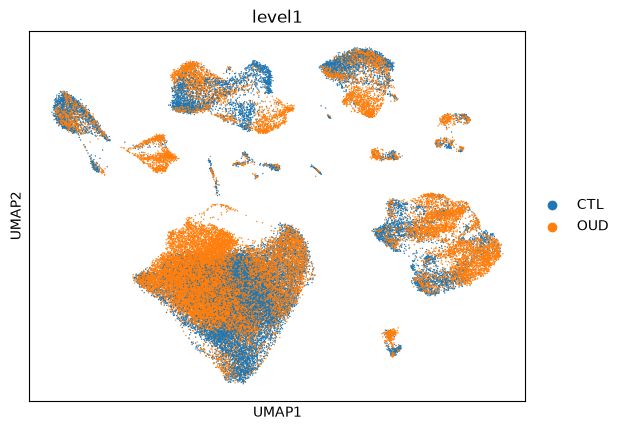

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\2358894899.py:10: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


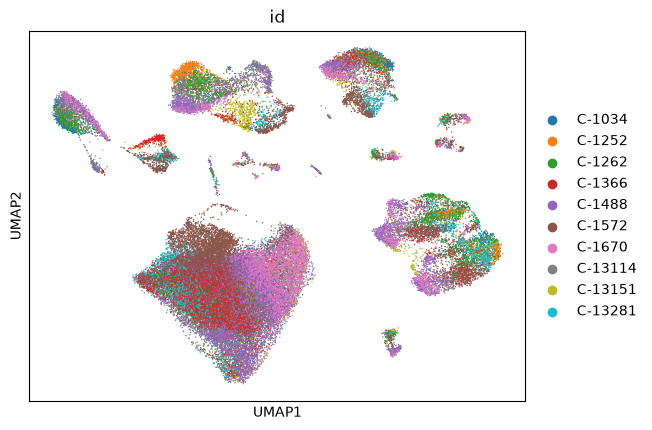

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\2358894899.py:16: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


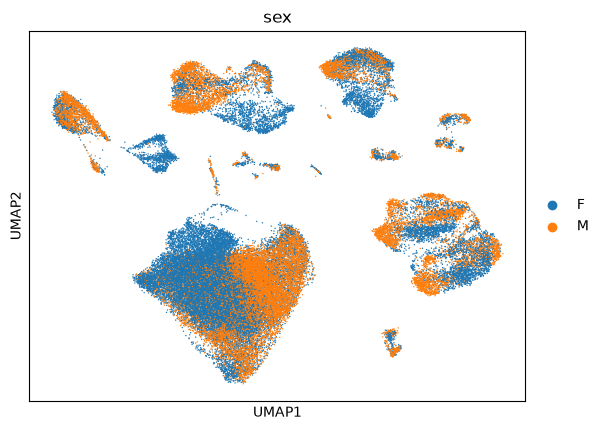

In [7]:
sc.settings.figdir = script_loc.parent / 'outputs_full/integration_figures'

#Create and save umap plots colored by diagnosis, sample, and sex for scdata
sc.pl.umap(
    scdata,
    color="level1",
    size=4,
    save='_dx_sc.png'
)
sc.pl.umap(
    scdata,
    color="id",
    size=4,
    save='_sample_sc.png'
)
sc.pl.umap(
    scdata,
    color="sex",
    size=4,
    save='_sex_sc.png'
)

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\3156492466.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


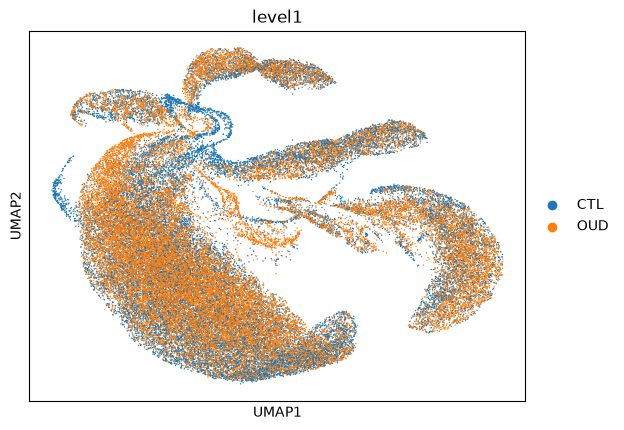

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\3156492466.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


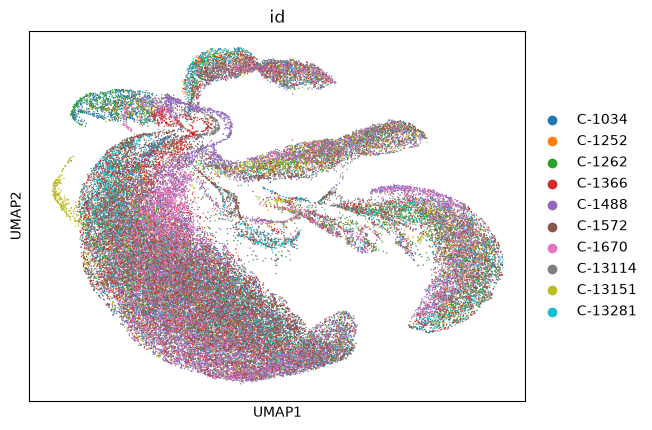

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\3156492466.py:14: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


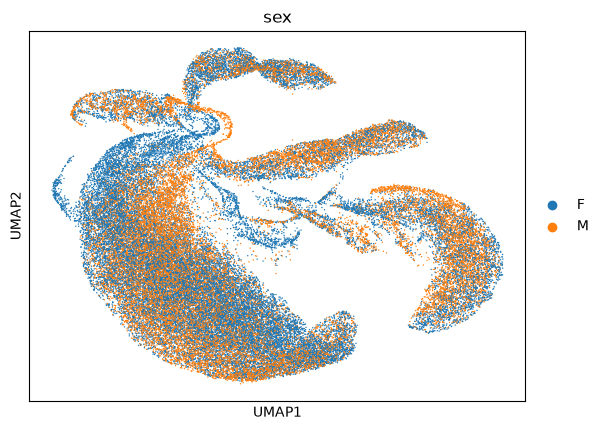

In [8]:
#Create and save umap plots colored by diagnosis, sample, and sex for hcdata
sc.pl.umap(
    hcdata,
    color="level1",
    size=4,
    save='_dx_hc.png'
)
sc.pl.umap(
    hcdata,
    color="id",
    size=4,
    save='_sample_hc.png'
)
sc.pl.umap(
    hcdata,
    color="sex",
    size=4,
    save='_sex_hc.png'
)

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\2811967.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


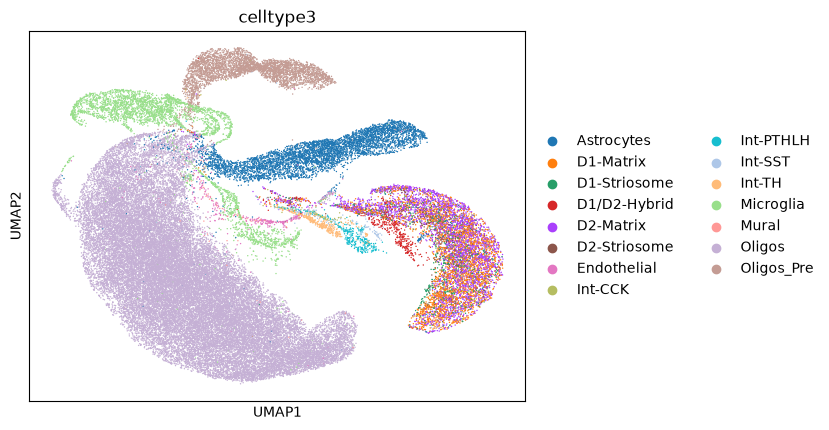

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\2811967.py:7: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


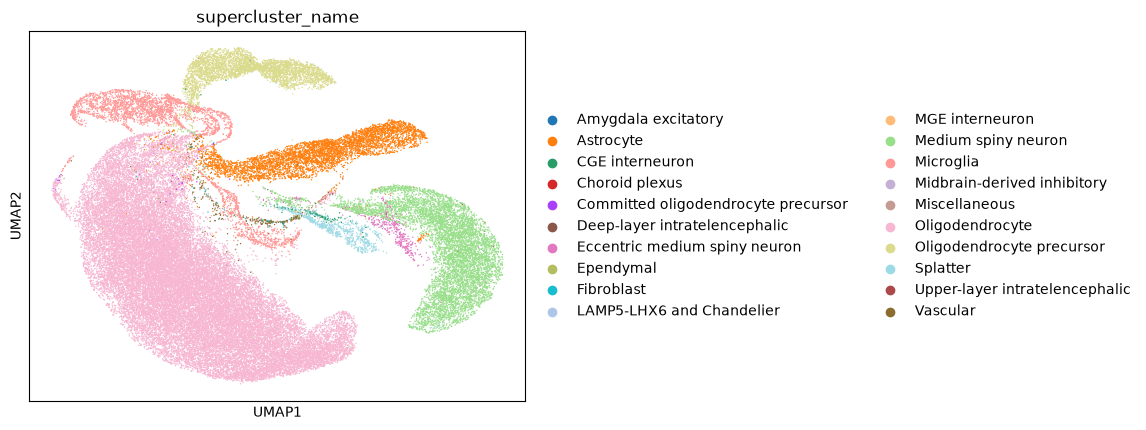

In [ ]:
#Plot UMAP over new cell types and given cell types for hcdata
sc.pl.umap(
    hcdata,
    color="celltype3",
    size=4,
    save='_givencells_hc.png'
)
sc.pl.umap(
    hcdata,
    color="supercluster_name",
    size=4,
    save='_mmcells_hc.png'
)


C:\Users\chris\AppData\Local\Temp\ipykernel_19320\1003638666.py:2: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


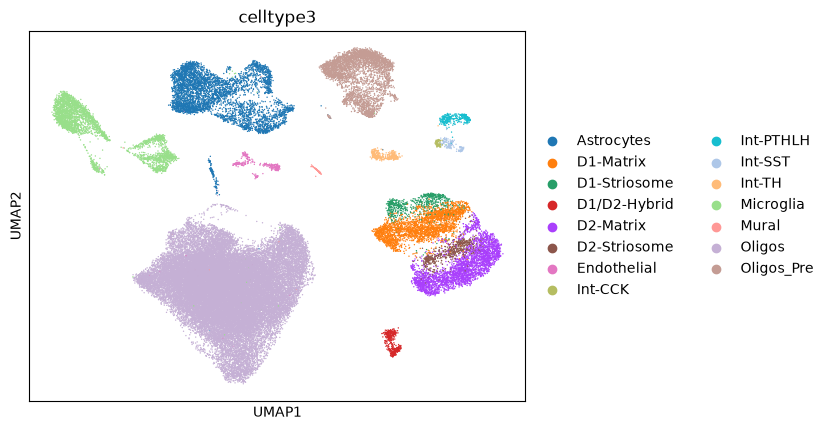

C:\Users\chris\AppData\Local\Temp\ipykernel_19320\1003638666.py:8: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(


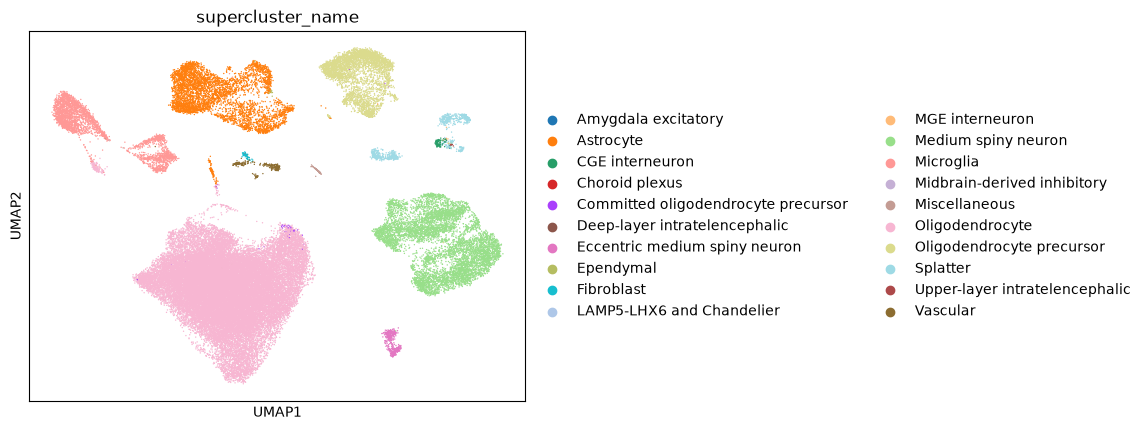

In [ ]:
#Plot UMAP over new cell types and given cell types for scdata
sc.pl.umap(
    scdata,
    color="celltype3",
    size=4,
    save='_givencells_sc.png'
)
sc.pl.umap(
    scdata,
    color="supercluster_name",
    size=4,
    save='_mmcells_sc.png'
)

In [11]:
#Write integrated data
hcdata.write_h5ad(data_loc / 'intermediate/hc_integrated')
scdata.write_h5ad(data_loc / 'intermediate/sc_integrated')